# RQ3 (part 2): challenges, desired improvements and future use of automated security tools

- **Q28**: challenges in automating security tools, by group (Direct/Indirect experience, Large/Small organization, Specialist/Non-specialist);
- **Q29**: desired improvements;
- **Q32** and **Q33**: intention to use automated security tools in the future, and which tools.

Q28 and Q29 were only shown to the participants who use automated security tools (Q23), so their percentages refer to them.

Outputs (`results/RQ3/`): `challenges_by_group.tex` (heatmap), `challenges_within_across_groups.tex`/`.xlsx`, `improvements_within_across_groups.tex`/`.xlsx`, and the group overlap figures `group_overlap_venn` and `group_overlap_sankey` (`.pdf`/`.png`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
pd.set_option('display.max_rows',None)
from pathlib import Path

# Output folder (created if it does not exist, e.g. in a fresh clone)
Path('results/RQ3').mkdir(parents=True, exist_ok=True)

In [2]:
data_path = Path('data')
df_o = pd.read_excel(data_path / 'survey_all_responses_ptbr.xlsx')

df = df_o[:]

df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace('\n', '', regex=True)

print(len(df))

#print(df.columns.tolist())

95


In [3]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())


df = df[~(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'] == 'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software')]
#df = df[~(df['Você costuma utilizar ferramentas de segurança automatizadas em seu dia a dia?'] == 'Não costumo utilizar')]

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())
print(df.shape)

<StringArray>
[                            'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software',
 'Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.',
                                           'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
Length: 3, dtype: str
<StringArray>
['Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.', 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
Length: 2, dtype: str
(83, 102)


In [4]:
df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()]

,Carimbo de data/hora,"Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.",Qual é a sua idade?,Em qual estado do Brasil você mora atualmente?,Qual é o seu gênero?,Qual é o seu nível de educação formal concluída?,Qual seu modelo de trabalho?,Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?,"Por favor, indique a senioridade da posição que ocupa.",Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?,...,Em quais fases do ciclo de desenvolvimento de software você costuma utilizar as ferramentas de segurança automatizadas selecionadas na pergunta anterior? (Selecione todas as opções que se aplicam),Quais recomendações você daria para um desenvolvedor sobre a adoção de ferramentas de segurança para seus projetos?,Quais são os principais desafios que você enfrenta ao automatizar ferramentas de segurança? (Selecione todas as opções que se aplicam),Quais melhorias você gostaria de ver nas ferramentas de segurança automatizadas que utiliza atualmente? (Selecione todas as opções que se aplicam),"Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email.","Quais são as razões pelas quais você opta por não utilizar ferramentas automatizadas de segurança de software? Por favor, descreva brevemente sobre.",Você considera utilizar ferramentas automatizadas de segurança de software em seus projetos no futuro?,"Se você respondeu ""Sim"" ou ""Talvez"" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque ""Nenhuma"" se respondeu ""Não"".","Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email..1",Marque a imagem em que aparece um filhote de cachorro:


In [5]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

df = df.drop(df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()].index, axis=0)

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

0
0


In [6]:
df['Qual é o seu nível de educação formal concluída?'].unique()

<StringArray>
[              'Mestrado', 'Estudante de Doutorado',        'Ensino Superior',
              'Doutorado',         'Especialização',           'Ensino Médio',
  'Estudante de Mestrado']
Length: 7, dtype: str

In [7]:
df.isna().sum()

Carimbo de data/hora                                                                                                                                                                                                                                                                                                                                                                                                                                            0
Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.     0
Qual é a sua idade?                                                                                 

In [8]:

df.shape

(83, 102)

In [9]:
direct_experience_col = (
    'Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'
)

years_experience_dev_col = (
    'Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?'
)

years_experience_sec_col = (
    'Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?'
)

education_level_col = 'Qual é o seu nível de educação formal concluída?'

seniority_col = 'Por favor, indique a senioridade da posição que ocupa.'

specialist_role_col = (
    'Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?'
)

certification_col = (
    'Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?'
)

has_experience_answer = (
    'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.'
)

# Answer groups
# Roles explicitly focused on software or information security. DevOps engineer
# alone is not considered evidence of security specialization; participants who
# also selected one of these roles remain specialists (roles are multiple choice)
specialist_answers = [
    "Cryptographer",
    "Penetration tester",
    "Privacy engineer",
    "Security engineer",
]


# Security roles written by participants in the "Outros" (free text) field of Q6
specialist_other_roles = [
    "SOC",
    "Gerente de Segurança da Informação",
    "Application secure",
    "Security Analyst",
    "Appsec",
    "AppSec",
    "Cybersegurança",
    "Security Champion",
    "Arquiteto de Segurança",
    "Information Security Analisty I / IAM",
    "Appsec & DevSecOps",
]


# The role question is multiple choice: answers come as a comma-separated
# string, so each selected role (predefined or written in "Outros") is checked
def is_specialist(answer):
    selected_roles = [role.strip() for role in str(answer).split(',')]
    return int(any(role in specialist_answers or role in specialist_other_roles
                   for role in selected_roles))

no_certification_answers = ["Não possui nenhuma certificação"]


In [10]:
df_direct_experience = df[df[direct_experience_col] == has_experience_answer]
df_indirect_experience = df[df[direct_experience_col] != has_experience_answer]

In [11]:
education_level_map = {
    'Ensino Médio': 1,
    'Ensino Superior': 2,
    'Especialização': 3,
    'Estudante de Mestrado': 4,
    'Mestrado': 5,
    'Estudante de Doutorado': 6,
    'Doutorado': 7
}

seniority_map = {
    'Estagiário': 1,
    'Júnior (até 5 anos)': 2,
    'Pleno (6 a 9 anos)': 3,
    'Sênior (10+ anos)': 4
}

years_experience_dev_map = {
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 5 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}

years_experience_sec_map = {
    'Nenhuma': 0,
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 6 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}


def direct_exp_specialist_interaction(row):
    if row['specialist'] and row['direct_experience']:
        return 3
    elif row['direct_experience'] and not row['specialist']:
        return 2
    else:
        return 1


def direct_exp_specialist_relation(row):
    return (row['specialist'] + row['direct_experience']) / 2


df[years_experience_dev_col] = df[years_experience_dev_col].map(
    years_experience_dev_map
)

df[seniority_col] = df[seniority_col].map(seniority_map)

df[years_experience_sec_col] = df[years_experience_sec_col].map(
    years_experience_sec_map
)


In [12]:
df['specialist'] = df[specialist_role_col].apply(is_specialist)

df['direct_experience'] = df[direct_experience_col].apply(
    lambda x: 1 if x == has_experience_answer else 0
)

df['certification'] = df[certification_col].apply(
    lambda x: 0 if x in no_certification_answers else 1
)

df[education_level_col] = df[education_level_col].map(
    education_level_map
)

df['direct_exp_specialist_interaction'] = df.apply(
    direct_exp_specialist_interaction, axis=1
)

df['direct_exp_specialist_relation'] = df.apply(
    direct_exp_specialist_relation, axis=1
)


In [13]:
education_level = df[education_level_col]
years_experience_dev = df[years_experience_dev_col]
years_experience_sec = df[years_experience_sec_col]
seniority = df[seniority_col]

direct_exp_specialist_interaction_col = df['direct_exp_specialist_interaction']
direct_exp_specialist_relation_col = df['direct_exp_specialist_relation']

certification = df['certification']


In [14]:
df.shape

(83, 107)

**Q28**

In [15]:
import re

# Definition of direct, indirect, large and small responses
direct_answer = 1
indirect_answer = 0

small_company_answers = [
    "Até 9 funcionários",
    "De 10 a 49 funcionários",
    "De 50 a 99 funcionários"
]

large_company_answers = [
    "De 100 a 499 funcionários",
    "De 500 a 999 funcionários",
    "Mais de 1000 funcionários"
]

specialist_answer = 1
non_specialist_answer = 0

# Correct column names
direct_experience_col = 'direct_experience'
company_size_col = 'Qual o tamanho da empresa para a qual você trabalha atualmente?'
specialist_col = 'specialist'
systems_col = 'Quais são os tipos de sistemas que você trabalha?'

# Filter direct and indirect responses
direct = df[df[direct_experience_col] == direct_answer].copy()
indirect = df[df[direct_experience_col] == indirect_answer].copy()

# Filter large and small companies
large_companies = df[df[company_size_col].isin(large_company_answers)].copy()
small_companies = df[df[company_size_col].isin(small_company_answers)].copy()

specialists = df[df[specialist_col] == specialist_answer].copy()
non_specialists = df[df[specialist_col] == non_specialist_answer].copy()


In [16]:
print("Number of participants in the Direct Experience group:", len(direct))
print("Number of participants in the Indirect Experience group:", len(indirect))
print("--"*35)

print("Number of participants in the Large Companies group:", len(large_companies))
print("Number of participants in the Small Companies group:", len(small_companies))
print("--"*35)

print("Number of participants in the Specialists group:", len(specialists))
print("Number of participants in the Non-Specialists group:",
      len(non_specialists))
print("--"*35)

print(f"Percentage of participants in the Large group: {len(large_companies)/88:.1f}")
print(f"Percentage of participants in the Small group: {len(small_companies)/88:.1f}")


Number of participants in the Direct Experience group: 62
Number of participants in the Indirect Experience group: 21
----------------------------------------------------------------------
Number of participants in the Large Companies group: 65
Number of participants in the Small Companies group: 16
----------------------------------------------------------------------
Number of participants in the Specialists group: 57
Number of participants in the Non-Specialists group: 26
----------------------------------------------------------------------
Percentage of participants in the Large group: 0.7
Percentage of participants in the Small group: 0.2


In [17]:
challenges_col = "Quais são os principais desafios que você enfrenta ao automatizar ferramentas de segurança? (Selecione todas as opções que se aplicam)"

In [18]:
challenge_options = [
    'Custo',
    'Curva de aprendizado',
    'Integração com outras ferramentas',
    'Performance do sistema',
    'Falsos positivos',
    'Falsos negativos',
    'Manutenção das ferramentas automatizadas',
    'Escalabilidade',
    'Falta de suporte técnico',
    'Compatibilidade com diferentes ambientes de desenvolvimento',
    'Necessidade de atualizações frequentes',
    'Aderência a normas e compliance',
    'Falta de visibilidade ou relatórios inadequados',
    'Outros'
]

challenge_map = {
    'Custo': 'Cost',
    'Curva de aprendizado': 'Learning curve',
    'Integração com outras ferramentas': 'Integration with other tools',
    'Performance do sistema': 'System performance',
    'Falsos positivos': 'False positives',
    'Falsos negativos': 'False negatives',
    'Manutenção das ferramentas automatizadas': 'Maintenance of automated tools',
    'Escalabilidade': 'Scalability',
    'Falta de suporte técnico': 'Lack of technical support',
    'Compatibilidade com diferentes ambientes de desenvolvimento': 'Compatibility with different development environments',
    'Necessidade de atualizações frequentes': 'Need for frequent updates',
    'Aderência a normas e compliance': 'Compliance and standards adherence',
    'Falta de visibilidade ou relatórios inadequados': 'Lack of visibility or inadequate reporting',
    'Outros': 'Other'
}


In [19]:
def count_responses(group_df):
    counts = {op: 0 for op in challenge_options}

    for _, row in group_df.iterrows():
        resp = row[challenges_col]
        if pd.isna(resp):
            continue

        choices = [op.strip() for op in resp.split(",")]

        for op in choices:
            if op in counts:
                counts[op] += 1
            else:
                counts["Outros"] += 1

    return pd.DataFrame.from_dict(counts, orient="index", columns=["Total"])


In [20]:
df_direct = count_responses(direct)
df_indirect = count_responses(indirect)

df_large = count_responses(large_companies)
df_small = count_responses(small_companies)

df_specialists = count_responses(specialists)
df_non_specialists = count_responses(non_specialists)

df_direct_en = df_direct.rename(index=challenge_map)
df_indirect_en = df_indirect.rename(index=challenge_map)

df_large_en = df_large.rename(index=challenge_map)
df_small_en = df_small.rename(index=challenge_map)

df_specialists_en = df_specialists.rename(index=challenge_map)
df_non_specialists_en = df_non_specialists.rename(index=challenge_map)



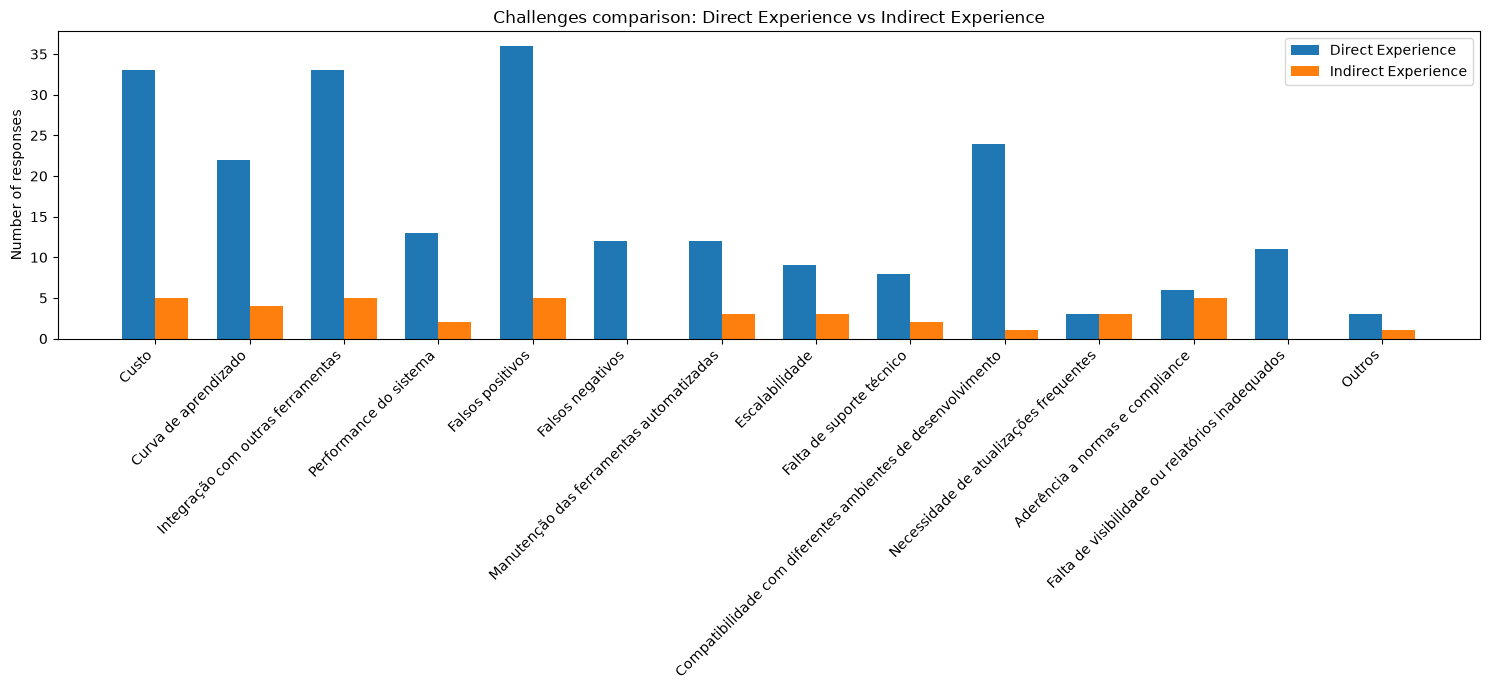

In [21]:
def comparison_chart(df1, df2, name1, name2):
    plt.figure(figsize=(15, 7))

    x = np.arange(len(df1.index))
    width = 0.35

    plt.bar(x - width/2, df1["Total"], width=width, label=name1)
    plt.bar(x + width/2, df2["Total"], width=width, label=name2)

    plt.xticks(x, df1.index, rotation=45, ha='right')
    plt.ylabel("Number of responses")
    plt.title(f"Challenges comparison: {name1} vs {name2}")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Direct vs Indirect
comparison_chart(df_direct, df_indirect, "Direct Experience", "Indirect Experience")


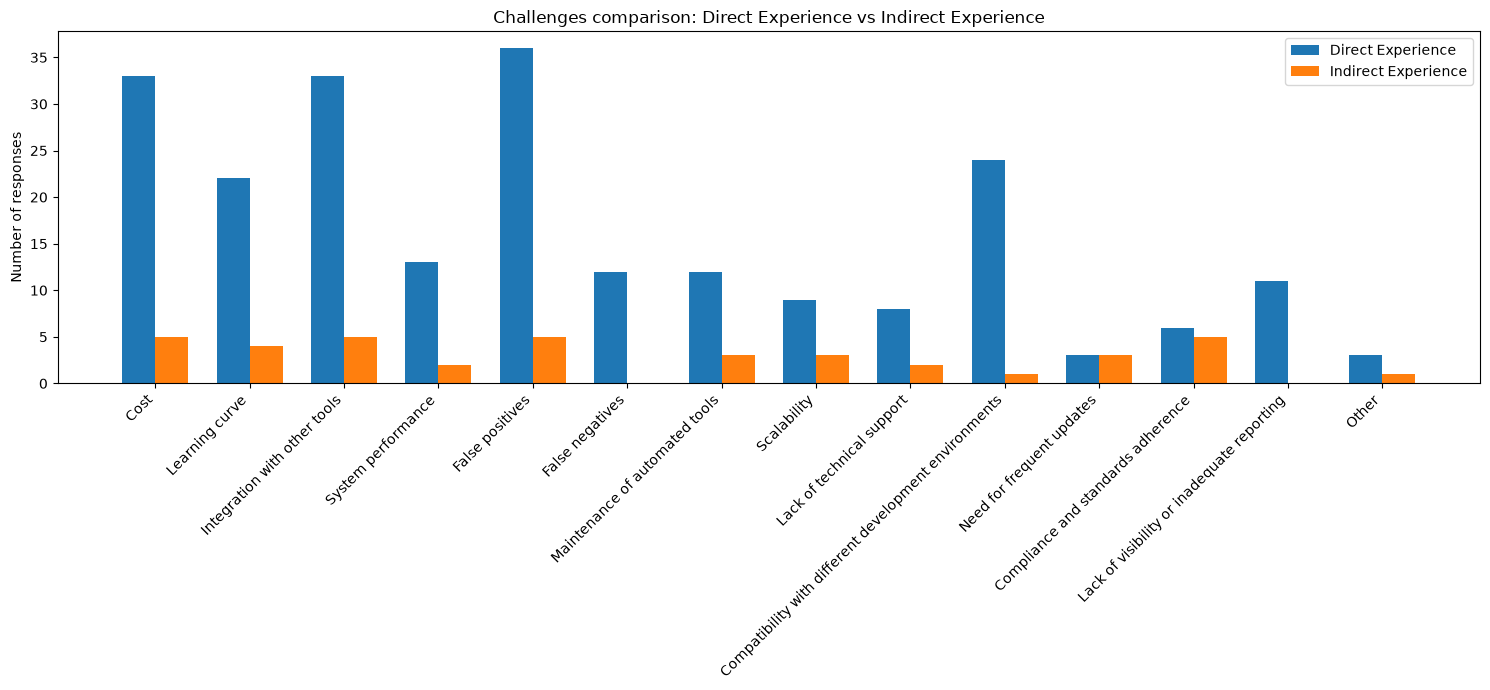

In [22]:
comparison_chart(df_direct_en, df_indirect_en,
                 "Direct Experience", "Indirect Experience")

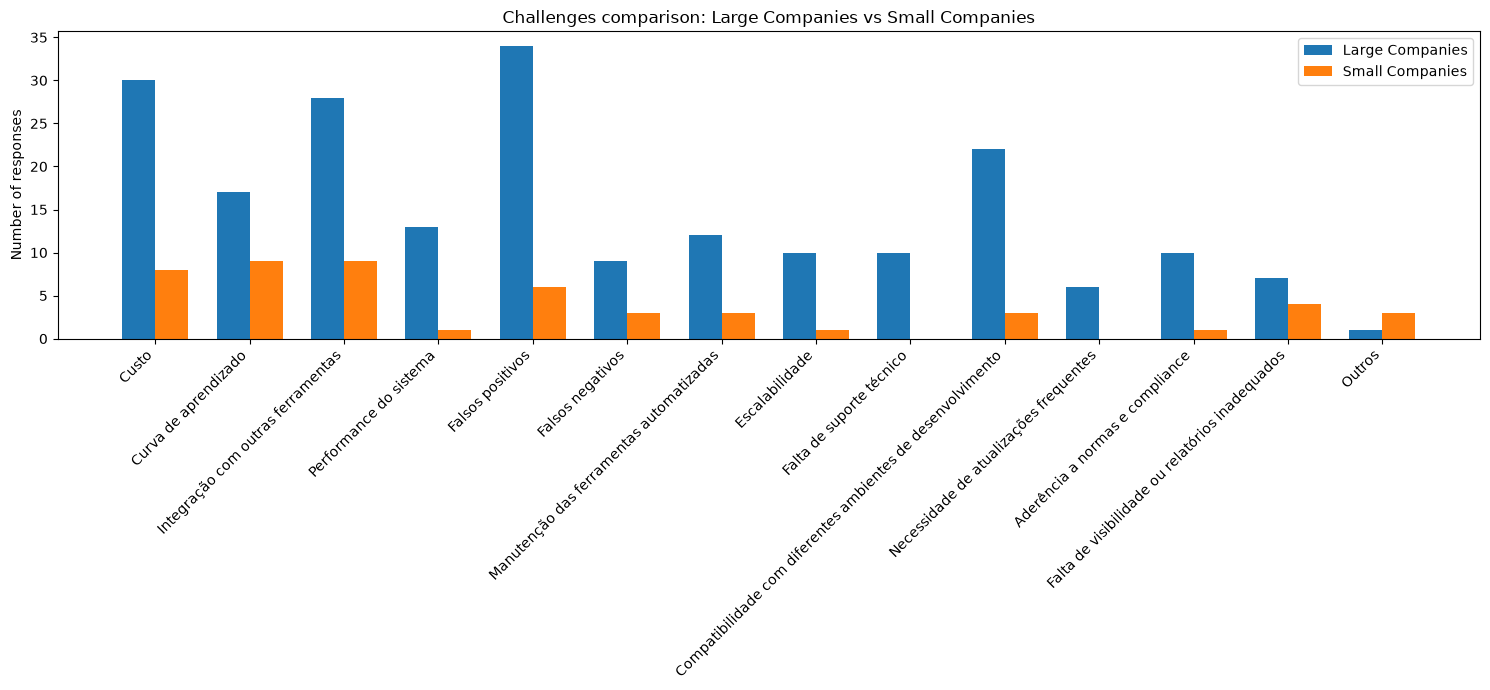

In [23]:
comparison_chart(df_large, df_small, "Large Companies", "Small Companies")

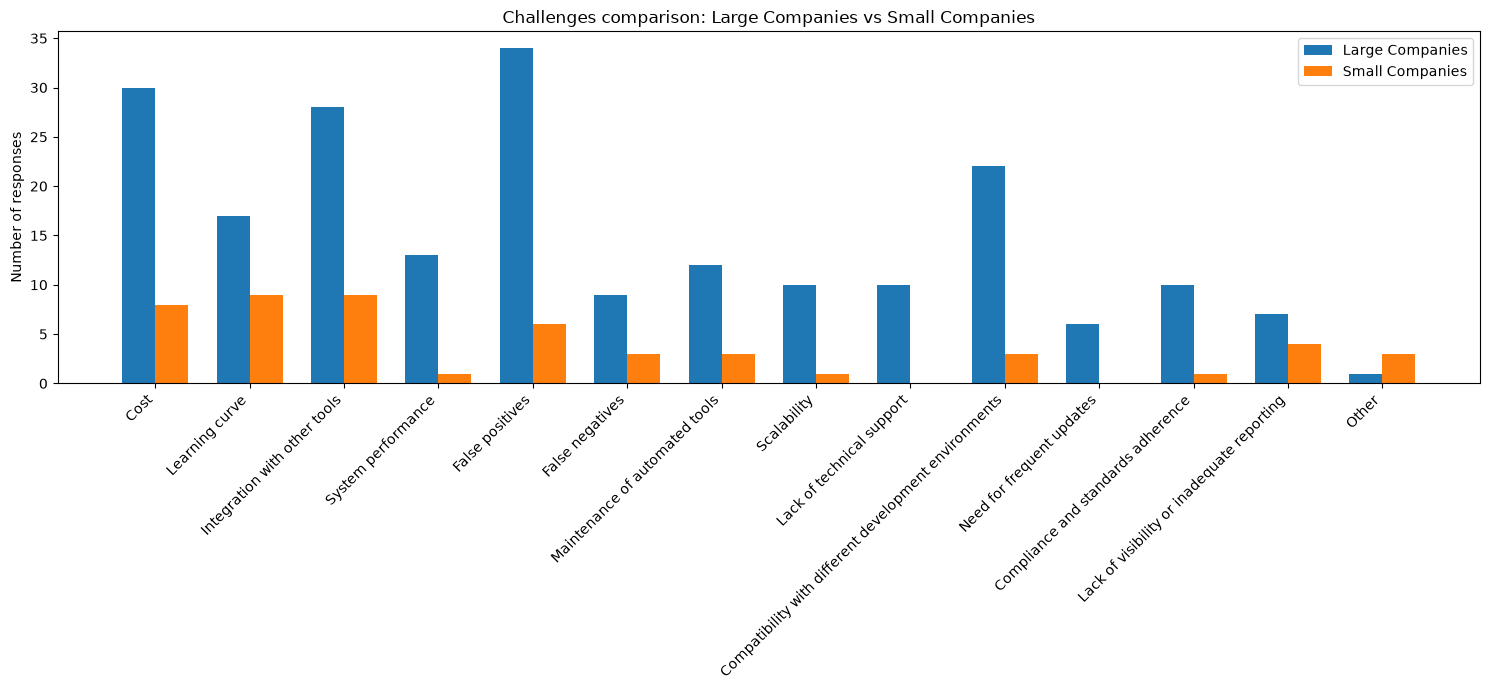

In [24]:
comparison_chart(df_large_en, df_small_en, "Large Companies", "Small Companies")

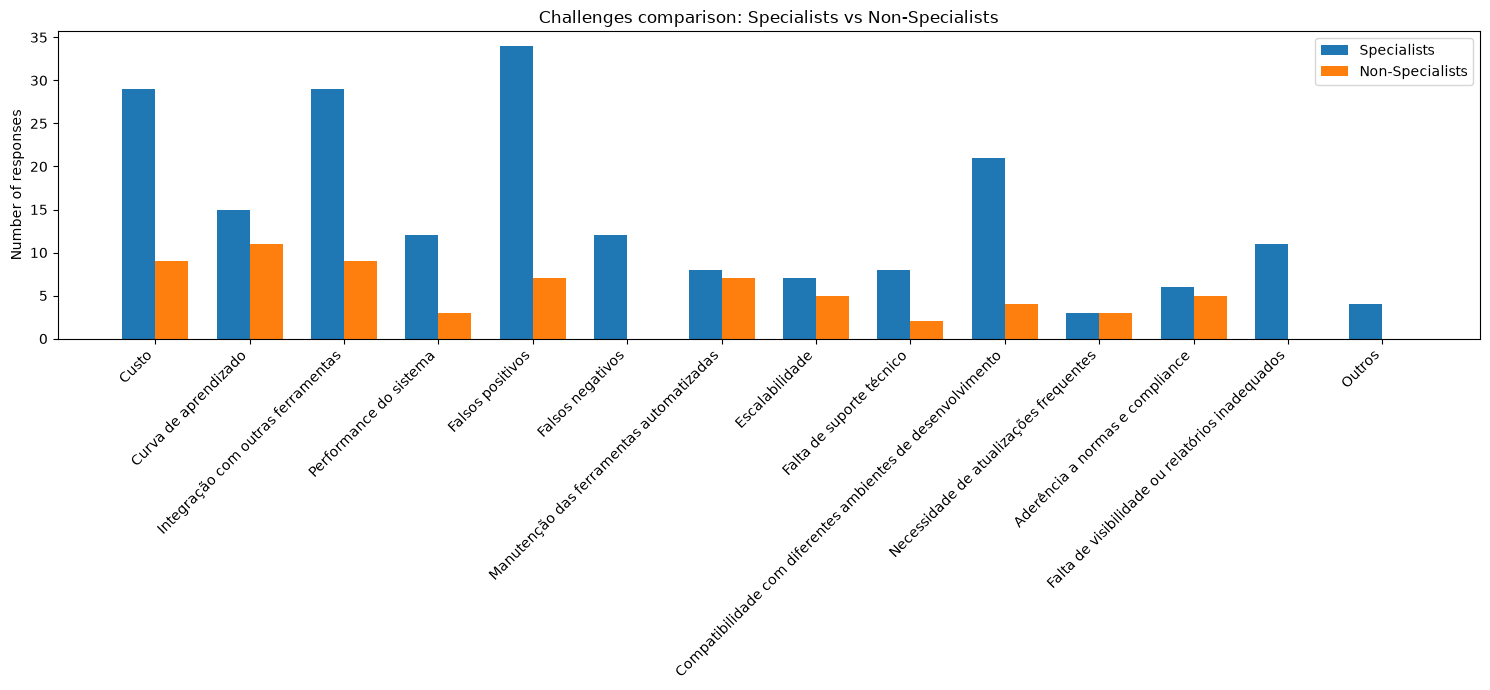

In [25]:
comparison_chart(df_specialists, df_non_specialists, "Specialists", "Non-Specialists")

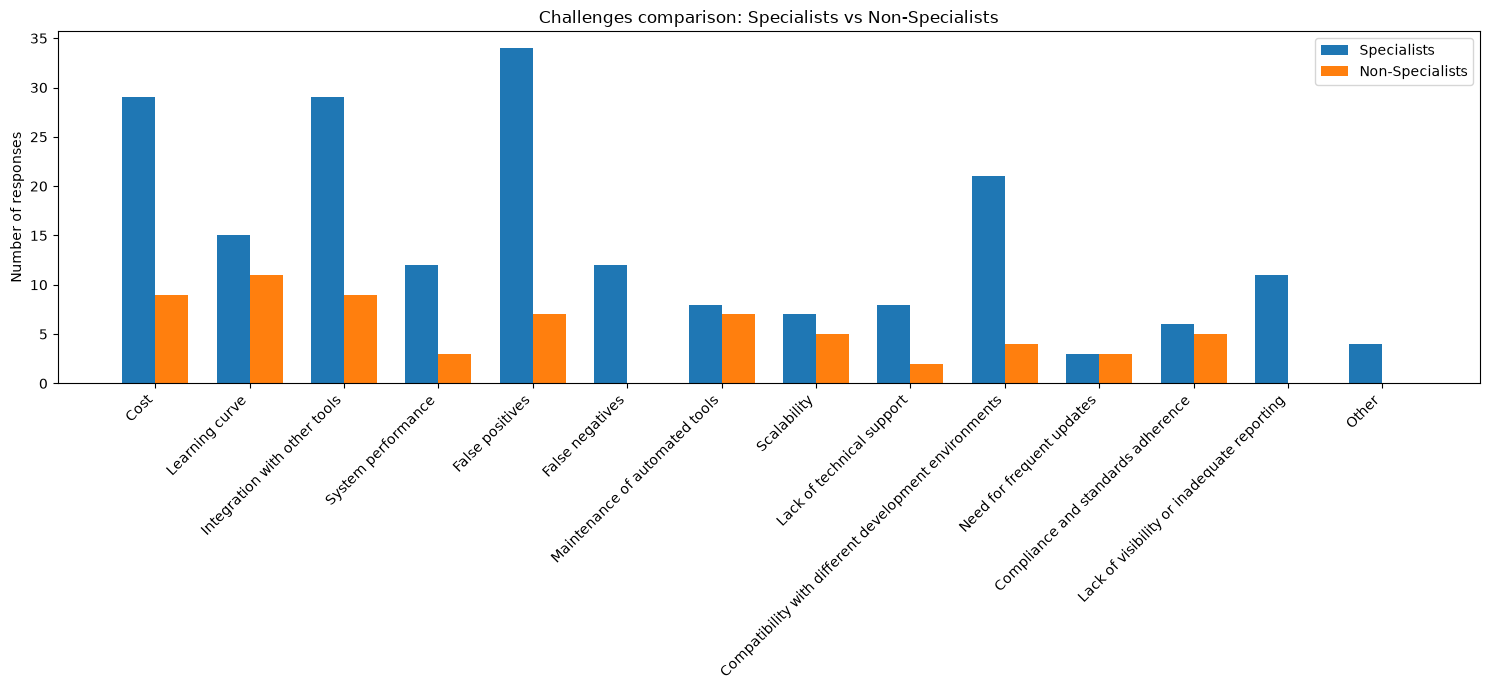

In [26]:
comparison_chart(df_specialists_en, df_non_specialists_en, "Specialists", "Non-Specialists")

**Q29**

In [27]:
improvements_col = 'Quais melhorias você gostaria de ver nas ferramentas de segurança automatizadas que utiliza atualmente? (Selecione todas as opções que se aplicam)'

In [28]:
improvements_options = [
    'Aumentar a abrangência das ameaças',
    'Menos falsos positivos',
    'Melhor integração com o CI/CD',
    'Melhor documentação e suporte',
    'Facilidade de uso',
    'Melhor usabilidade da interface',
    'Redução do tempo de análise',
    'Melhor compatibilidade com diferentes ambientes de desenvolvimento',
    'Relatórios mais detalhados e customizáveis'
]

In [29]:
col = df[improvements_col].dropna()

In [30]:
exploded_answers = (
    col.str.split(',')
       .explode()
       .str.strip()
)

In [31]:
count = exploded_answers.value_counts()
print(exploded_answers.unique())

<StringArray>
[                                            'Menos falsos positivos',
                                      'Melhor integração com o CI/CD',
 'Melhor compatibilidade com diferentes ambientes de desenvolvimento',
                                                  'Facilidade de uso',
                                      'Melhor documentação e suporte',
                                        'Redução do tempo de análise',
                                    'Melhor usabilidade da interface',
                                 'Aumentar a abrangência das ameaças',
                         'Relatórios mais detalhados e customizáveis',
                                    'Feedback e aprendizado contínuo',
                                                   'Redução no custo',
                                                  'nao posso opninar',
          'Formatação de findings em padrão estipulado como o SARIF.',
                                                  'Customizar r

In [32]:
table = count.reset_index()
table.columns = ["Answer", "Frequency"]

print("\n=== Answer frequency table ===\n")
print(table)


=== Answer frequency table ===

                                               Answer  Frequency
0                              Menos falsos positivos         48
1                       Melhor integração com o CI/CD         41
2   Melhor compatibilidade com diferentes ambiente...         27
3                       Melhor documentação e suporte         26
4                                   Facilidade de uso         23
5                  Aumentar a abrangência das ameaças         21
6                         Redução do tempo de análise         20
7          Relatórios mais detalhados e customizáveis         18
8                     Melhor usabilidade da interface         13
9                     Feedback e aprendizado contínuo          1
10                                   Redução no custo          1
11                                  nao posso opninar          1
12  Formatação de findings em padrão estipulado co...          1
13                                  Customizar regras    

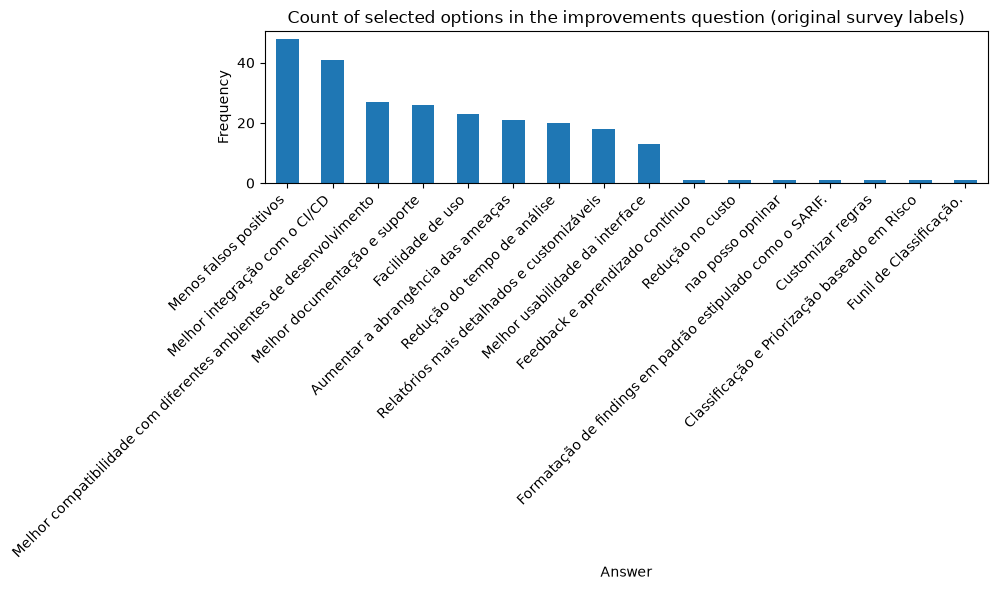

In [33]:
plt.figure(figsize=(10, 6))
count.plot(kind='bar')
plt.xlabel("Answer")
plt.ylabel("Frequency")
plt.title("Count of selected options in the improvements question (original survey labels)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [34]:
translate_map = {
    'Menos falsos positivos': 'Fewer false positives',
    'Melhor integração com o CI/CD': 'Better CI/CD integration',
    'Melhor compatibilidade com diferentes ambientes de desenvolvimento': 'Better compatibility with different development environments',
    'Facilidade de uso': 'Ease of use',
    'Melhor documentação e suporte': 'Better documentation and support',
    'Redução do tempo de análise': 'Reduced analysis time',
    'Melhor usabilidade da interface': 'Better interface usability',
    'Aumentar a abrangência das ameaças': 'Increase threat coverage',
    'Relatórios mais detalhados e customizáveis': 'More detailed and customizable reports',
    'Feedback e aprendizado contínuo': 'Continuous feedback and learning',
    'Redução no custo': 'Cost reduction',
    'nao posso opninar': 'I cannot give an opinion',
    'Formatação de findings em padrão estipulado como o SARIF.': 'Findings formatting in a standardized format such as SARIF',
    'Customizar regras': 'Custom rule configuration',
    'Classificação e Priorização baseado em Risco': 'Risk-based classification and prioritization',
    'Funil de Classificação.': 'Classification funnel'
}


exploded_answers_en = exploded_answers.map(
    lambda x: translate_map.get(x, x)  # keeps the original text when there is no translation
)

count_en = exploded_answers_en.value_counts()





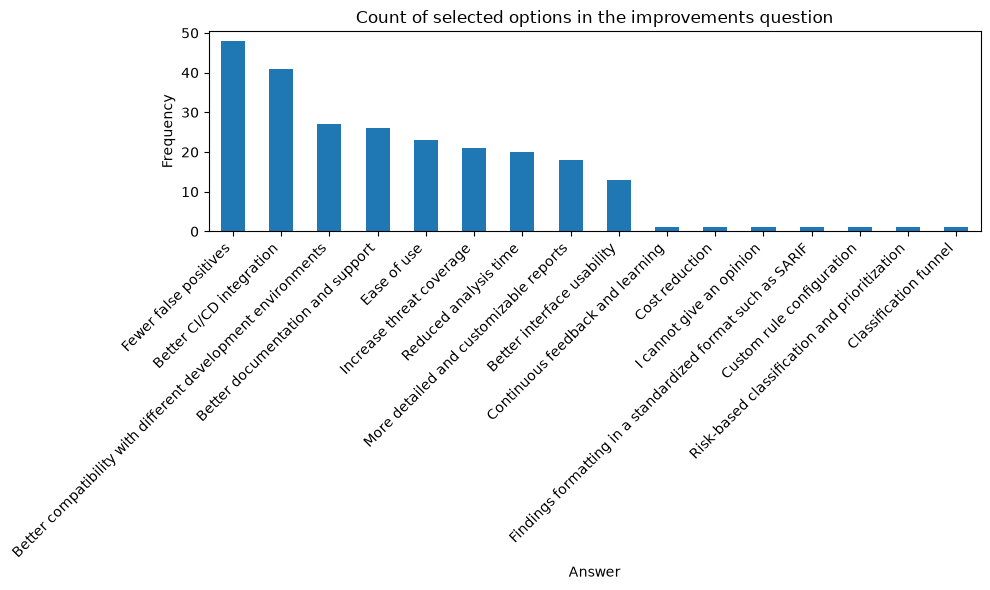

In [35]:
plt.figure(figsize=(10, 6))
count_en.plot(kind='bar')
plt.xlabel("Answer")
plt.ylabel("Frequency")
plt.title("Count of selected options in the improvements question")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Q32**

In [36]:
future_col = 'Você considera utilizar ferramentas automatizadas de segurança de software em seus projetos no futuro?'

In [37]:
valid_options = ['Sim', 'Não', 'Talvez']

In [38]:
answers = (
    df[future_col]
    .dropna()
    .astype(str)
    .str.strip()
)


In [39]:
df = df[df[future_col].isin(valid_options)]

In [40]:
count = answers.value_counts().reindex(valid_options, fill_value=0)

In [41]:
table = count.reset_index()
table.columns = ["Answer", "Frequency"]

print("\n=== Answer frequency table ===\n")
print(table)


=== Answer frequency table ===

   Answer  Frequency
0     Sim          6
1     Não          2
2  Talvez          6


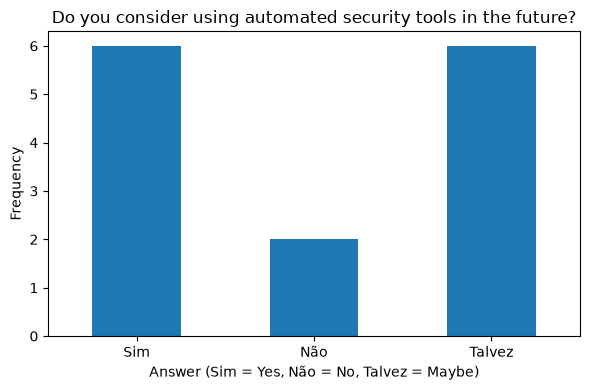

In [42]:
plt.figure(figsize=(6, 4))
count.plot(kind='bar')
plt.xlabel("Answer (Sim = Yes, Não = No, Talvez = Maybe)")
plt.ylabel("Frequency")
plt.title("Do you consider using automated security tools in the future?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Q33**

In [43]:
future_tools_col = 'Se você respondeu "Sim" ou "Talvez" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque "Nenhuma" se respondeu "Não".'

In [44]:
future_tool_options = [
    'Nenhuma', 'Dependabot', 'PHP Security Checker', 'Snyk', 'Clair', 'Blackduck', 'Retire.JS', 'SRC:CLR', 'Anchore', 'Node Security Platform',
    'Trivy', 'Sonatype', 'Whitesource', 'CodeQL', 'CheckStyle', 'Coverity', 'SonarQube', 'Bandit', 'PHPStan', 'LGTM',
    'Brakeman', 'Qark', 'ESLint Security', 'Dart Analyzer', 'Checkmarx', 'DevSkim', 'CFN NAG', 'SpotBugs', 'Chef', 'Ansible',
    'Terraform', 'Puppet', 'Phan', 'Seccomp', 'CloudCustodian', 'Turbot', 'Bane', 'Ansible-Lint', 'Blackbox', 'Puppet-Lint',
    'InSpec', 'Kube Audit', 'Foodcritic', 'Cookstyle', 'conftest', 'Pinterest Knox', 'GitLeaks', 'CyberArk Conjur', 'ThoughtWorks Talisman', 'Berglas',
    'Docker Secrets', 'Trufflehog', 'AppScan', 'Fortify'

]

print(len(future_tool_options))

54


In [45]:
col_f = df[future_tools_col].dropna()

In [46]:
exploded_answers = (
    col_f.str.split(',')
       .explode()
       .str.strip()
)

In [47]:
count = exploded_answers.value_counts()

In [48]:
table = count.reset_index()
table.columns = ["Tool", "Frequency"]

print("\n=== FREQUENCY TABLE FOR FUTURE TOOLS ===\n")
print(table)


=== FREQUENCY TABLE FOR FUTURE TOOLS ===

                                           Tool  Frequency
0                                     Retire.JS          4
1                                     SonarQube          4
2                                      GitLeaks          4
3                                      Blackbox          4
4                                CloudCustodian          4
5                          PHP Security Checker          3
6                                       AppScan          3
7                                       Ansible          3
8                                     Terraform          3
9                                Docker Secrets          3
10                                      Nenhuma          3
11                       Node Security Platform          2
12                                       CodeQL          2
13                                      PHPStan          2
14                              CyberArk Conjur          2
15           

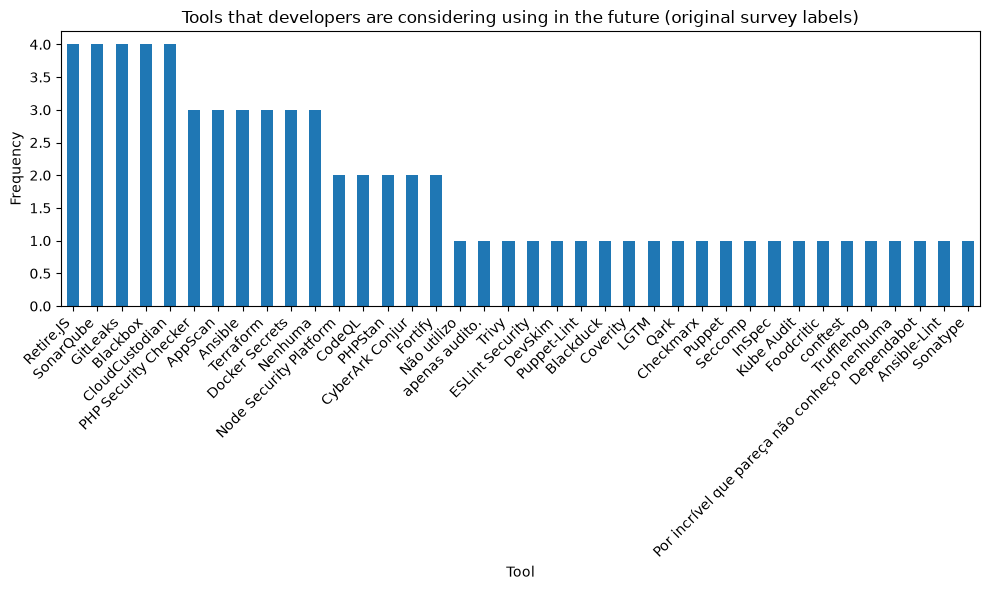

In [49]:
plt.figure(figsize=(10, 6))
count.plot(kind='bar')
plt.xlabel("Tool")
plt.ylabel("Frequency")
plt.title("Tools that developers are considering using in the future (original survey labels)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

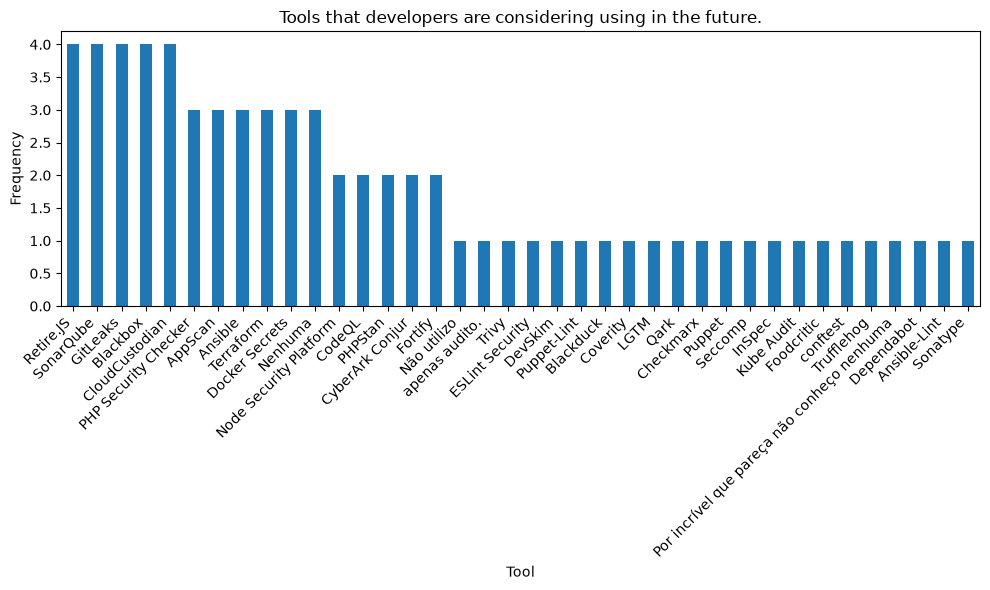

In [50]:
plt.figure(figsize=(10, 6))
count.plot(kind='bar')
plt.xlabel("Tool")
plt.ylabel("Frequency")
plt.title("Tools that developers are considering using in the future.")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [51]:
df[future_col] = (
    df[future_col]
      .astype(str)
      .str.strip()
      .str.capitalize()
)

# Keep only valid answers
df = df[df[future_col].isin(valid_options)]


# -----------------------------
# COUNTING FUNCTION
# -----------------------------

def count_tools_by_group(df, group_answer):
    # Filter participants from the selected group
    subset = df[df[future_col] == group_answer][future_tools_col].dropna()

    # Fix multiple separators
    subset = subset.str.replace("; ", ",").str.replace(";", ",")

    # Properly explode
    answers = (
        subset
        .astype(str)
        .str.split(",")      # split by comma
        .explode()           # transform list into rows
        .str.strip()         # remove spaces
        .replace("", pd.NA)  # remove empty items
        .dropna()
    )

    # Count EVERYTHING (no filtering by predefined options)
    return answers.value_counts()


# -----------------------------
# COUNT BY GROUP
# -----------------------------

count_yes = count_tools_by_group(df, "Sim")
count_not = count_tools_by_group(df, "Não")
count_maybe = count_tools_by_group(df, "Talvez")


# -----------------------------
# DISPLAY TABLES
# -----------------------------

print("\n=== Tools mentioned by those who answered 'Yes' ===\n")
print(count_yes.reset_index().rename(columns={'index': 'Tool', 'count': 'Frequency'}))

print("\n=== Tools mentioned by those who answered 'No' ===\n")
print(count_not.reset_index().rename(columns={'index': 'Tool', 'count': 'Frequency'}))

print("\n=== Tools mentioned by those who answered 'Maybe' ===\n")
print(count_maybe.reset_index().rename(columns={'index': 'Tool', 'count': 'Frequency'}))



=== Tools mentioned by those who answered 'Yes' ===

   Se você respondeu "Sim" ou "Talvez" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque "Nenhuma" se respondeu "Não".  \
0                                PHP Security Checker                                                                                               
1                                           Retire.JS                                                                                               
2                                           Terraform                                                                                               
3                                      CloudCustodian                                                                                               
4                                            GitLeaks                                                                                               
5                                      Docker Secret

In [52]:
df[future_tools_col].unique()

<StringArray>
[                                                                                                                                                                                                                                                                       'PHP Security Checker, Retire.JS, SonarQube',
                                                                                                                                                                                                                                                                                      'Retire.JS, GitLeaks, AppScan',
                                                                                                                                                                                                                                                                                      'SonarQube, Blackbox, AppScan',
                                                        

## Q28 challenges heatmap (LaTeX)

Generates `results/RQ3/challenges_by_group.tex`: a standalone TikZ/pgfplots figure with the number and percentage of participants in each group who reported each challenge. Q28 was only shown to the participants who use automated security tools (Q23 = "Sim" or "Uso parcialmente"), so group sizes and percentages refer to them. "Outros" (Other) is not shown.

In [53]:
# Challenges in the order of the figure, with their labels
heatmap_challenges = [
    ('Custo', 'Cost'),
    ('Curva de aprendizado', 'Learning curve'),
    ('Integração com outras ferramentas', 'Integration with other tools'),
    ('Performance do sistema', 'System performance'),
    ('Falsos positivos', 'False positives'),
    ('Manutenção das ferramentas automatizadas', 'Tool maintenance'),
    ('Escalabilidade', 'Scalability'),
    ('Falta de suporte técnico', 'Lack of technical support'),
    ('Compatibilidade com diferentes ambientes de desenvolvimento', 'Environment compatibility'),
    ('Necessidade de atualizações frequentes', 'Frequent updates'),
    ('Aderência a normas e compliance', 'Standards and compliance'),
    ('Falsos negativos', 'False negatives'),
    ('Falta de visibilidade ou relatórios inadequados', 'Lack of visibility\\\\or inadequate reporting'),
]

# Q28 was only shown to the participants who use automated security tools (Q23 = "Sim" or
# "Uso parcialmente"): group sizes and percentages refer to them. The counts already include only
# them, because the other participants did not answer Q28
heatmap_participants = pd.concat([direct, indirect])
heatmap_tool_users = set(heatmap_participants.index[
    heatmap_participants['Você costuma utilizar ferramentas de segurança automatizadas em seu dia a dia?']
    .isin(['Sim', 'Uso parcialmente'])
])


def tool_users_in(group):
    """Number of participants of the group who use automated security tools."""
    return len(set(group.index) & heatmap_tool_users)


# (title, group 1 label, group 2 label, group 1 counts, group 2 counts, group 1 size, group 2 size)
heatmap_blocks = [
    ('Direct vs. Indirect', 'Direct', 'Indirect',
     df_direct, df_indirect, tool_users_in(direct), tool_users_in(indirect)),
    ('Large vs. Small', 'Large', 'Small',
     df_large, df_small, tool_users_in(large_companies), tool_users_in(small_companies)),
    ('Specialist vs. Non-specialist', 'Spec.', 'Non-spec.',
     df_specialists, df_non_specialists, tool_users_in(specialists), tool_users_in(non_specialists)),
]

# Color scale: 0% to 65%, or up to the next multiple of 5 above the highest percentage
max_percentage = max(
    counts.loc[challenge, 'Total'] / size * 100
    for _, _, _, counts1, counts2, size1, size2 in heatmap_blocks
    for counts, size in ((counts1, size1), (counts2, size2))
    for challenge, _ in heatmap_challenges
)
meta_max = max(65, 5 * int(-(-max_percentage // 5)))

PLOT_OPTIONS = r"""
\addplot[
    matrix plot*,
    mesh/cols=2,
    draw=black,
    line width=0.09pt,
    point meta=explicit,
    visualization depends on={
        value \thisrow{count} \as \mycount
    },
    visualization depends on={
        value \thisrow{perc} \as \myperc
    },
    nodes near coords={
        \shortstack{
            \pgfmathprintnumber[fixed,precision=0]{\mycount}\\[-1pt]
            {\scriptsize(
            \pgfmathprintnumber[fixed,precision=0]{\myperc}\%)}
        }
    },
    nodes near coords align={center},
    every node near coord/.style={
        font=\tiny,
        align=center
    }
]
table[meta=perc]{
x y count perc
"""


def heatmap_axis(index, title, label1, label2, counts1, counts2, size1, size2):
    """One axis (block) of the heatmap: two columns of groups, one row per challenge."""
    name = 'ABC'[index]
    if index == 0:
        position = ['    at={(0,0)},', '    anchor=west,', '    xshift=1.2cm,']
        y_labels = ['    yticklabels={'] + [
            f'        {label}' + (',' if k < len(heatmap_challenges) - 1 else '')
            for k, (_, label) in enumerate(heatmap_challenges)
        ] + ['    },']
        y_label_style = [
            '    y tick label style={',
            '        font=\\tiny,',
            '        text width=4.8cm,',
            '        align=right',
            '    },',
        ]
    else:
        position = [f'    at={{({"ABC"[index - 1]}.east)}},', '    xshift=0.9cm,', '    anchor=west,']
        y_labels = ['    yticklabels={},']
        y_label_style = []

    colorbar = [
        '    colorbar,',
        '    colorbar style={',
        '        width=1.5mm,',
        '        font=\\tiny,',
        '        ylabel={Participants (\\%)},',
        '        ylabel style={font=\\tiny},',
        '        ytick={' + ','.join(str(t) for t in range(0, meta_max + 1, 10)) + '},',
        '        yticklabel style={font=\\tiny}',
        '    },',
    ] if index == 2 else []

    options = [
        '\\begin{axis}[',
        f'    name={name},',
        *position,
        '    width=4.1cm,',
        '    height=7.8cm,',
        '    view={0}{90},',
        '    enlargelimits=false,',
        f'    title={{\\textbf{{{title}}}}},',
        '    title style={font=\\scriptsize},',
        '    xtick={1,2},',
        f'    xticklabels={{{label1}, {label2}}},',
        f'    ytick={{1,...,{len(heatmap_challenges)}}},',
        *y_labels,
        '    y dir=reverse,',
        '    tick label style={font=\\tiny},',
        *y_label_style,
        '    colormap name=redyellowdarkgreen,',
        '    point meta min=0,',
        f'    point meta max={meta_max},',
        *colorbar,
        '    axis line style={draw=none},',
        '    xtick style={draw=none},',
        '    ytick style={draw=none}',
        ']',
    ]

    rows = []
    for y, (challenge, _) in enumerate(heatmap_challenges, start=1):
        for x, (counts, size) in enumerate(((counts1, size1), (counts2, size2)), start=1):
            count = int(counts.loc[challenge, 'Total'])
            rows.append(f'{x} {y:>2} {count:>3} {count / size * 100:>5.1f}')
        rows.append('')

    return '\n'.join(options) + '\n' + PLOT_OPTIONS + '\n'.join(rows[:-1]) + '\n};\n\n\\end{axis}\n'


# Every participant is either in the direct or in the indirect experience group
total_participants = len(heatmap_tool_users)

blocks_tex = []
for index, (title, label1, label2, counts1, counts2, size1, size2) in enumerate(heatmap_blocks):
    name1, name2 = title.split(' vs. ')
    comment = [f'% BLOCK {index + 1}: {title.upper()}', f'% {name1} = {size1}', f'% {name2} = {size2}']
    excluded = total_participants - size1 - size2
    if excluded:
        verb = 'are' if excluded > 1 else 'is'
        comment.append(f'% {excluded} participant{"s" if excluded > 1 else ""} {verb} not in either group and {verb} excluded.')
    separator = '% ' + '=' * 70
    blocks_tex.append('\n'.join([separator, *comment, separator, '']) + '\n'
                      + heatmap_axis(index, title, label1, label2, counts1, counts2, size1, size2))

heatmap_tex = r"""\documentclass[border={1mm 0mm}]{standalone}
\usepackage[utf8]{inputenc}
\usepackage[english]{babel}
\usepackage{graphicx}
\usepackage{pgf}
\usepackage{tikz}
\usetikzlibrary{positioning,arrows.meta}
\usepackage{pgfplots}
\pgfplotsset{compat=1.18}

\begin{document}


\pgfplotsset{
  colormap={redyellowdarkgreen}{
    rgb(0cm)=(0.99,0.83,0.80)
    rgb(1.5cm)=(0.996,0.917,0.658)
    rgb(3cm)=(0.14,0.55,0.27)
  }
}
\begin{tikzpicture}

% Group sizes and percentages refer to the participants who use automated
% security tools, fully or partially (Q23), the only ones asked Q28.

""" + '\n\n'.join(blocks_tex) + r"""
\end{tikzpicture}

\end{document}
"""

heatmap_path = Path('results/RQ3') / 'challenges_by_group.tex'
heatmap_path.write_text(heatmap_tex, encoding='utf-8')
print(f'Saved: {heatmap_path}')

Saved: results/RQ3/challenges_by_group.tex


### Check: two cells of the Q28 heatmap

Recounts, directly from the answers and without `count_responses`, the two cells that differ from the previous version of the figure in the paper:

- Direct / Lack of technical support (paper: 2, 3.2%)
- Indirect / Lack of visibility or inadequate reporting (paper: 3, 14.3%)

The counts of Direct and Indirect must add up to the total of all participants, since every participant is in one of the two groups. Percentages refer to the participants who use automated security tools (Q23), as in the heatmap.

In [54]:
# Challenges to check: (label in the figure, option in the survey, keyword, values in the paper for Direct and Indirect)
challenges_to_check = [
    ('Lack of technical support', 'Falta de suporte técnico', 'suporte', {'Direct': 2, 'Indirect': 2}),
    ('Lack of visibility or inadequate reporting', 'Falta de visibilidade ou relatórios inadequados', 'visibilidade',
     {'Direct': 11, 'Indirect': 3}),
]


def chose_option(answer, option):
    """True if the option is one of the comma-separated choices of the answer."""
    return option in [choice.strip() for choice in str(answer).split(',')]


# Original question that defines the Direct/Indirect groups
experience_question = (
    'Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software '
    'no processo de desenvolvimento de software?'
)

# Every participant is in one of the two groups
all_participants = pd.concat([direct.assign(Group='Direct'), indirect.assign(Group='Indirect')])
print(f'Participants: Direct {len(direct)} + Indirect {len(indirect)} = {len(all_participants)}')
print(f'Who use automated security tools (Q23): Direct {tool_users_in(direct)} + Indirect {tool_users_in(indirect)}'
      f' = {len(heatmap_tool_users)}')

for label, option, keyword, paper_values in challenges_to_check:
    chose = all_participants[challenges_col].apply(lambda answer: chose_option(answer, option))

    # Participants counted, with the row of data/survey_all_responses_ptbr.xlsx
    # (Excel row = DataFrame index + 2: header row and 0-based index)
    counted = pd.DataFrame({
        'Excel row': all_participants.index[chose] + 2,
        'Group': all_participants.loc[chose, 'Group'],
        'Experience answer': all_participants.loc[chose, experience_question],
        'Q28 answer (column CQ)': all_participants.loc[chose, challenges_col],
    }).sort_values(['Group', 'Excel row']).reset_index(drop=True)

    counts = counted['Group'].value_counts().reindex(['Direct', 'Indirect'], fill_value=0)
    print(f'\n=== {label} ("{option}") ===')
    print(f'Total: {int(chose.sum())} | Direct {counts["Direct"]} ({counts["Direct"] / tool_users_in(direct) * 100:.1f}%)'
          f' + Indirect {counts["Indirect"]} ({counts["Indirect"] / tool_users_in(indirect) * 100:.1f}%)'
          f' | Paper: Direct {paper_values["Direct"]} + Indirect {paper_values["Indirect"]}')
    with pd.option_context('display.max_colwidth', None):
        display(counted)

    # Answers that mention the keyword but were not counted (none expected)
    mentions = all_participants[challenges_col].astype(str).str.contains(keyword, case=False)
    not_counted = all_participants.loc[mentions & ~chose, ['Group', challenges_col]]
    print(f'Answers mentioning "{keyword}" that were not counted: {len(not_counted)}')
    if len(not_counted):
        with pd.option_context('display.max_colwidth', None):
            display(not_counted)

Participants: Direct 62 + Indirect 21 = 83
Who use automated security tools (Q23): Direct 56 + Indirect 13 = 69

=== Lack of technical support ("Falta de suporte técnico") ===
Total: 10 | Direct 8 (14.3%) + Indirect 2 (15.4%) | Paper: Direct 2 + Indirect 2


,Excel row,Group,Experience answer,Q28 answer (column CQ)
0,14,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Integração com outras ferramentas, Falsos positivos, Falsos negativos, Falta de suporte técnico, Compatibilidade com diferentes ambientes de desenvolvimento, Aderência a normas e compliance"
1,30,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Integração com outras ferramentas, Falsos positivos, Escalabilidade, Falta de suporte técnico, Compatibilidade com diferentes ambientes de desenvolvimento, Falta de visibilidade ou relatórios inadequados"
2,49,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Curva de aprendizado, Integração com outras ferramentas, Falsos positivos, Manutenção das ferramentas automatizadas, Escalabilidade, Falta de suporte técnico"
3,56,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Falsos positivos, Escalabilidade, Falta de suporte técnico"
4,62,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Integração com outras ferramentas, Performance do sistema, Manutenção das ferramentas automatizadas, Falta de suporte técnico, Compatibilidade com diferentes ambientes de desenvolvimento, Aderência a normas e compliance"
5,69,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Falsos positivos, Falta de suporte técnico"
6,79,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Curva de aprendizado, Integração com outras ferramentas, Performance do sistema, Falsos positivos, Falta de suporte técnico, Compatibilidade com diferentes ambientes de desenvolvimento, Necessidade de atualizações frequentes"
7,83,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Curva de aprendizado, Integração com outras ferramentas, Falsos positivos, Manutenção das ferramentas automatizadas, Falta de suporte técnico, Falta de visibilidade ou relatórios inadequados"
8,16,Indirect,"Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.","Curva de aprendizado, Falsos positivos, Falta de suporte técnico, Aderência a normas e compliance"
9,45,Indirect,"Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.","Custo, Curva de aprendizado, Integração com outras ferramentas, Falta de suporte técnico, Aderência a normas e compliance"


Answers mentioning "suporte" that were not counted: 0

=== Lack of visibility or inadequate reporting ("Falta de visibilidade ou relatórios inadequados") ===
Total: 11 | Direct 11 (19.6%) + Indirect 0 (0.0%) | Paper: Direct 11 + Indirect 3


,Excel row,Group,Experience answer,Q28 answer (column CQ)
0,30,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Integração com outras ferramentas, Falsos positivos, Escalabilidade, Falta de suporte técnico, Compatibilidade com diferentes ambientes de desenvolvimento, Falta de visibilidade ou relatórios inadequados"
1,41,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Integração com outras ferramentas, Compatibilidade com diferentes ambientes de desenvolvimento, Falta de visibilidade ou relatórios inadequados"
2,48,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Integração com outras ferramentas, Falsos positivos, Falta de visibilidade ou relatórios inadequados"
3,64,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Curva de aprendizado, Integração com outras ferramentas, Falsos positivos, Falsos negativos, Manutenção das ferramentas automatizadas, Falta de visibilidade ou relatórios inadequados"
4,65,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Curva de aprendizado, Falta de visibilidade ou relatórios inadequados"
5,66,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Integração com outras ferramentas, Performance do sistema, Falsos positivos, Falta de visibilidade ou relatórios inadequados"
6,74,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Curva de aprendizado, Integração com outras ferramentas, Falsos positivos, Falta de visibilidade ou relatórios inadequados"
7,78,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Integração com outras ferramentas, Falsos positivos, Falta de visibilidade ou relatórios inadequados"
8,80,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,Falta de visibilidade ou relatórios inadequados
9,81,Direct,Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.,"Custo, Falsos positivos, Falsos negativos, Falta de visibilidade ou relatórios inadequados"


Answers mentioning "visibilidade" that were not counted: 0


## Overlap between the comparison groups (Venn diagram)

Number of participants in each combination of the three groupings used in RQ2 and RQ3: Direct vs. Indirect experience, Specialist vs. Non-specialist, and Large vs. Small company. Participants outside a circle belong to the complementary group (Indirect, Non-specialist, Small). Participants who did not report the company size are in neither Large nor Small and are counted outside the Large circle.

The figure is saved as `results/RQ3/group_overlap_venn.pdf` and `.png`.

Participants: 83 | Direct 62 | Specialist 57 | Large 65 | Small 16 | Unknown size 2


,Region,Participants,Unknown company size
0,"Direct, Specialist, Large",39,0
1,"Direct, Specialist, not Large",13,1
2,"Direct, Non-specialist, Large",8,0
3,"Direct, Non-specialist, not Large",2,0
4,"Indirect, Specialist, Large",5,0
5,"Indirect, Specialist, not Large",0,0
6,"Indirect, Non-specialist, Large",13,0
7,"Indirect, Non-specialist, not Large",3,1


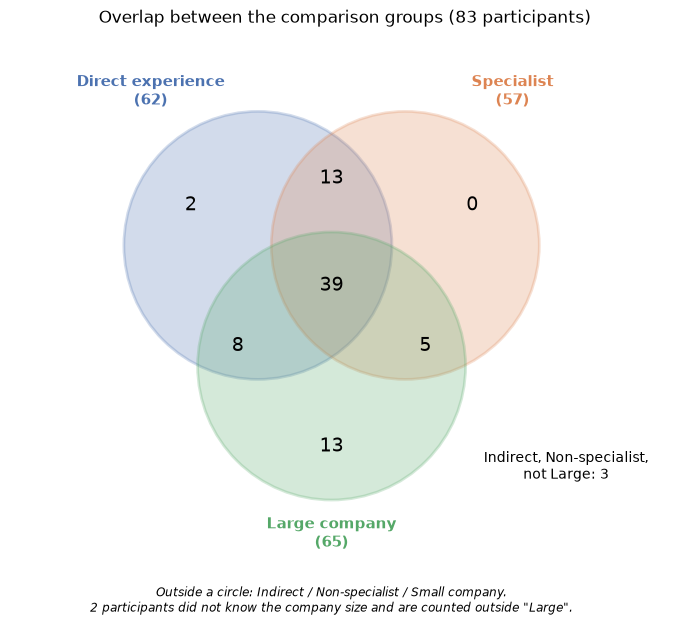

Saved: results/RQ3/group_overlap_venn.pdf and results/RQ3/group_overlap_venn.png


In [55]:
from matplotlib.patches import Circle

# Participant sets (DataFrame indexes); every participant is either Direct or Indirect
all_ids = set(direct.index) | set(indirect.index)
direct_ids = set(direct.index)
specialist_ids = set(specialists.index)
large_ids = set(large_companies.index)
unknown_size_ids = all_ids - large_ids - set(small_companies.index)

# The eight regions of the diagram: (in Direct, in Specialist, in Large) -> participants
regions = {
    (d, s, l): {
        i for i in all_ids
        if (i in direct_ids) == d and (i in specialist_ids) == s and (i in large_ids) == l
    }
    for d in (True, False) for s in (True, False) for l in (True, False)
}
assert sum(len(ids) for ids in regions.values()) == len(all_ids)

region_names = {
    (True, True, True): 'Direct, Specialist, Large',
    (True, True, False): 'Direct, Specialist, not Large',
    (True, False, True): 'Direct, Non-specialist, Large',
    (False, True, True): 'Indirect, Specialist, Large',
    (True, False, False): 'Direct, Non-specialist, not Large',
    (False, True, False): 'Indirect, Specialist, not Large',
    (False, False, True): 'Indirect, Non-specialist, Large',
    (False, False, False): 'Indirect, Non-specialist, not Large',
}
overlap_table = pd.DataFrame([
    {'Region': region_names[key], 'Participants': len(ids),
     'Unknown company size': len(ids & unknown_size_ids)}
    for key, ids in regions.items()
])
print(f'Participants: {len(all_ids)} | Direct {len(direct_ids)} | Specialist {len(specialist_ids)}'
      f' | Large {len(large_ids)} | Small {len(small_companies)} | Unknown size {len(unknown_size_ids)}')
display(overlap_table)

# --- Diagram ---
fig, ax = plt.subplots(figsize=(7, 6.5))
circles = [
    ((-0.55, 0.3), f'Direct experience\n({len(direct_ids)})', (-1.35, 1.45), '#4C72B0'),
    ((0.55, 0.3), f'Specialist\n({len(specialist_ids)})', (1.35, 1.45), '#DD8452'),
    ((0.0, -0.6), f'Large company\n({len(large_ids)})', (0.0, -1.85), '#55A868'),
]
for center, label, label_position, color in circles:
    ax.add_patch(Circle(center, 1.0, facecolor=color, alpha=0.25, edgecolor=color, linewidth=2))
    ax.text(*label_position, label, ha='center', va='center', fontsize=11, fontweight='bold', color=color)

# Position of the count of each region
region_positions = {
    (True, True, True): (0.0, 0.0),
    (True, True, False): (0.0, 0.8),
    (True, False, True): (-0.7, -0.45),
    (False, True, True): (0.7, -0.45),
    (True, False, False): (-1.05, 0.6),
    (False, True, False): (1.05, 0.6),
    (False, False, True): (0.0, -1.2),
}
for key, position in region_positions.items():
    ax.text(*position, str(len(regions[key])), ha='center', va='center', fontsize=14)

outside = regions[(False, False, False)]
ax.text(1.75, -1.35, f'Indirect, Non-specialist,\nnot Large: {len(outside)}', ha='center', va='center', fontsize=10)
ax.text(0.0, -2.35,
        'Outside a circle: Indirect / Non-specialist / Small company.\n'
        f'{len(unknown_size_ids)} participants did not know the company size and are counted outside "Large".',
        ha='center', va='center', fontsize=8.5, style='italic')

ax.set_xlim(-2.4, 2.6)
ax.set_ylim(-2.6, 1.9)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(f'Overlap between the comparison groups ({len(all_ids)} participants)', fontsize=12)
plt.tight_layout()

venn_path = Path('results/RQ3') / 'group_overlap_venn'
fig.savefig(venn_path.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(venn_path.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {venn_path}.pdf and {venn_path}.png')

## Overlap between the comparison groups (Sankey diagram)

Flow of the participants from experience (Direct/Indirect) to specialization (Specialist/Non-specialist) and company size (Large/Small/Unknown). The width of each link is the number of participants.

The figure is saved as `results/RQ3/group_overlap_sankey.pdf` and `.png` (static export requires the `kaleido` package).

Links (from -> to: participants):
  Direct experience -> Specialist: 52
  Direct experience -> Non-specialist: 10
  Indirect experience -> Specialist: 5
  Indirect experience -> Non-specialist: 16
  Specialist -> Large company: 44
  Specialist -> Small company: 12
  Specialist -> Unknown size: 1
  Non-specialist -> Large company: 21
  Non-specialist -> Small company: 4
  Non-specialist -> Unknown size: 1


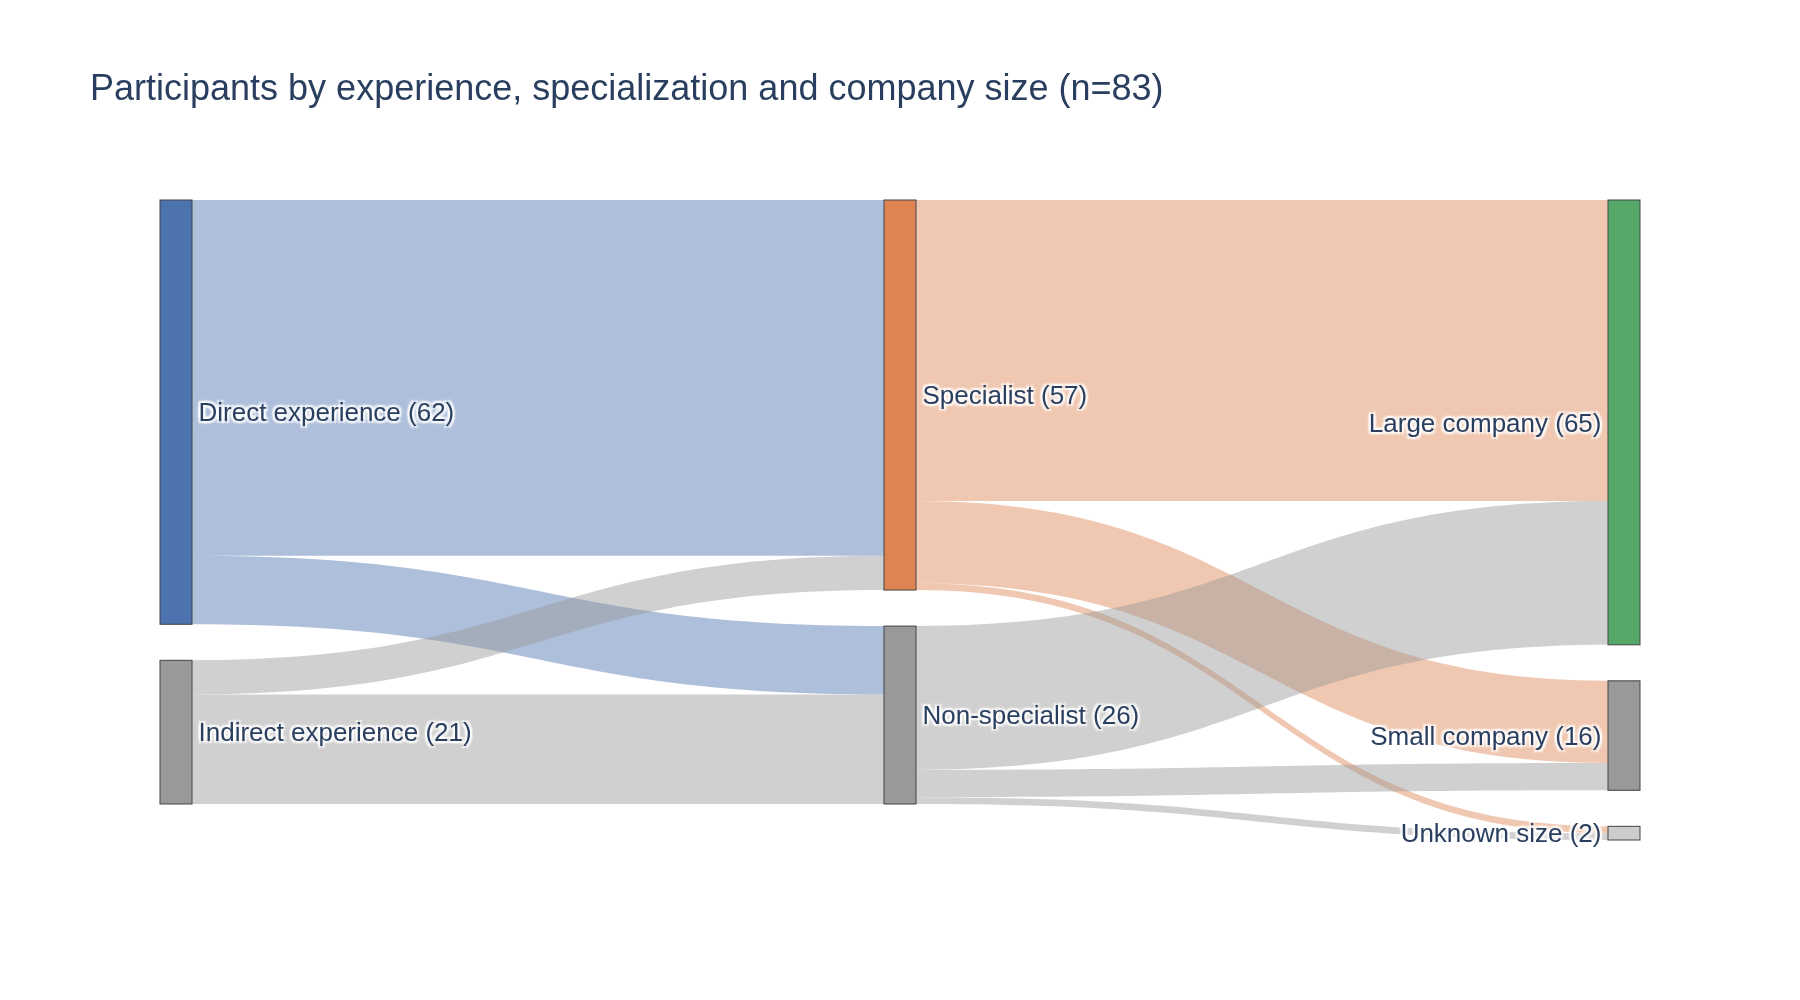

Saved: results/RQ3/group_overlap_sankey.pdf and results/RQ3/group_overlap_sankey.png


In [56]:
from IPython.display import Image

# Participant sets (DataFrame indexes); every participant is either Direct or Indirect
all_ids = set(direct.index) | set(indirect.index)
sankey_levels = [
    {'Direct experience': set(direct.index), 'Indirect experience': set(indirect.index)},
    {'Specialist': set(specialists.index), 'Non-specialist': set(non_specialists.index)},
    {'Large company': set(large_companies.index), 'Small company': set(small_companies.index),
     'Unknown size': all_ids - set(large_companies.index) - set(small_companies.index)},
]
node_colors = {
    'Direct experience': '#4C72B0', 'Indirect experience': '#999999',
    'Specialist': '#DD8452', 'Non-specialist': '#999999',
    'Large company': '#55A868', 'Small company': '#999999', 'Unknown size': '#CCCCCC',
}
link_colors = {
    'Direct experience': 'rgba(76,114,176,0.45)', 'Indirect experience': 'rgba(150,150,150,0.45)',
    'Specialist': 'rgba(221,132,82,0.45)', 'Non-specialist': 'rgba(150,150,150,0.45)',
}

node_names = [name for level in sankey_levels for name in level]
node_index = {name: i for i, name in enumerate(node_names)}
node_sizes = {name: len(ids) for level in sankey_levels for name, ids in level.items()}

sources, targets, values, colors = [], [], [], []
for level, next_level in zip(sankey_levels, sankey_levels[1:]):
    for name, ids in level.items():
        for next_name, next_ids in next_level.items():
            count = len(ids & next_ids)
            if count:
                sources.append(node_index[name])
                targets.append(node_index[next_name])
                values.append(count)
                colors.append(link_colors[name])

print('Links (from -> to: participants):')
for source, target, value in zip(sources, targets, values):
    print(f'  {node_names[source]} -> {node_names[target]}: {value}')

sankey_fig = go.Figure(go.Sankey(
    arrangement='snap',
    node=dict(
        label=[f'{name} ({node_sizes[name]})' for name in node_names],
        color=[node_colors[name] for name in node_names],
        pad=18,
        thickness=16,
    ),
    link=dict(source=sources, target=targets, value=values, color=colors),
))
sankey_fig.update_layout(
    title_text=f'Participants by experience, specialization and company size (n={len(all_ids)})',
    font_size=13,
    width=900,
    height=500,
)

sankey_path = Path('results/RQ3') / 'group_overlap_sankey'
sankey_fig.write_image(sankey_path.with_suffix('.png'), scale=2)
sankey_fig.write_image(sankey_path.with_suffix('.pdf'))
# Shows the saved image, which renders in any notebook viewer
display(Image(filename=sankey_path.with_suffix('.png'), width=900))
print(f'Saved: {sankey_path}.pdf and {sankey_path}.png')

## Q28 and Q29 by group: overall, single grouping factors and combinations (tables)

`group_comparison_table` counts how many participants selected each option of a multiple choice question:

- **All** participants;
- each **single grouping factor**: experience (Direct/Indirect), role (Specialist/Non-specialist) and organization size (Large/Small);
- each **combination** of the three factors (combinations without participants are omitted).

Each cell shows the count and, in parentheses, the percentage within the column (rounded half up). Options are sorted by overall frequency. Participants who did not know the organization size are in *All*, *Experience* and *Role*, but not in *Org. size* or in the combinations.

The `percentage_base` argument (default: `PERCENTAGE_BASE`) defines who is counted in each column, that is, N and the denominator of the percentages:

- `'group'`: all participants of the group;
- `'tool_users'`: only the participants of the group who use automated security tools, fully or partially (Q23 = "Sim" or "Uso parcialmente"). Q28 and Q29 were only shown to these participants;
- `'respondents'`: only the participants of the group who answered the question.

In [57]:
import math

# Default denominator of the percentages: 'group' (all participants), 'tool_users' (participants who
# use automated security tools in Q23) or 'respondents' (participants who answered the question)
PERCENTAGE_BASE = 'group'

# Q23: use of automated security tools; Q28 and Q29 were only shown to those who use them
tool_use_col = 'Você costuma utilizar ferramentas de segurança automatizadas em seu dia a dia?'
tool_use_answers = ['Sim', 'Uso parcialmente']

# All participants (df itself is filtered later in the notebook, in the Q32 analysis)
participants = pd.concat([direct, indirect])

experience_groups = {'Direct': set(direct.index), 'Indirect': set(indirect.index)}
role_groups = {'Spec.': set(specialists.index), 'Non-spec.': set(non_specialists.index)}
size_groups = {'Large': set(large_companies.index), 'Small': set(small_companies.index)}

NUMBER_WORDS = {1: 'one', 2: 'two', 3: 'three', 4: 'four', 5: 'five', 6: 'six', 7: 'seven', 8: 'eight', 9: 'nine'}


def chose_option(answer, option):
    """True if the option is one of the comma-separated choices of the answer."""
    return option in [choice.strip() for choice in str(answer).split(',')]


def count_with_percentage(count, n):
    """'count (percentage\\%)', with the percentage rounded half up."""
    percentage = (200 * count + n) // (2 * n)
    return f'{count} ({percentage}\\%)'


def group_comparison_table(question_col, options, item_name, caption, label, file_name,
                           percentage_base=None):
    """
    Builds the table of a multiple choice question by group and saves it as .tex and .xlsx.

    options: list of (option in the survey, label in the table), in the order used for ties.
    item_name: name of the options in the header (e.g. 'Challenge').
    percentage_base: 'group', 'tool_users' or 'respondents' (default: PERCENTAGE_BASE).
    """
    percentage_base = percentage_base or PERCENTAGE_BASE
    answered = set(participants.index[participants[question_col].notna()])
    tool_users = set(participants.index[participants[tool_use_col].isin(tool_use_answers)])

    # Columns: (column name, participant ids)
    single_columns = [('All', set(participants.index))] + [
        (name, ids) for groups in (experience_groups, role_groups, size_groups) for name, ids in groups.items()
    ]
    combinations = {
        experience: [
            (role, size, e_ids & r_ids & s_ids)
            for role, r_ids in role_groups.items()
            for size, s_ids in size_groups.items()
            if e_ids & r_ids & s_ids
        ]
        for experience, e_ids in experience_groups.items()
    }
    omitted = [
        (experience, role, size)
        for experience, e_ids in experience_groups.items()
        for role, r_ids in role_groups.items()
        for size, s_ids in size_groups.items()
        if not e_ids & r_ids & s_ids
    ]
    columns = single_columns + [
        (f'{experience} & {role} & {size}', ids)
        for experience, combos in combinations.items()
        for role, size, ids in combos
    ]
    if percentage_base == 'tool_users':
        columns = [(name, ids & tool_users) for name, ids in columns]
    elif percentage_base == 'respondents':
        columns = [(name, ids & answered) for name, ids in columns]

    # Counts: one row per option, sorted by overall frequency (ties keep the order of the options)
    counts = pd.DataFrame(
        {name: [sum(chose_option(answer, option) for answer in participants.loc[sorted(ids), question_col])
                for option, _ in options]
         for name, ids in columns},
        index=[option_label for _, option_label in options],
    )
    counts = counts.loc[counts['All'].sort_values(ascending=False, kind='stable').index]
    sizes = {name: len(ids) for name, ids in columns}

    # --- Spreadsheet ---
    percentages = (counts / pd.Series(sizes) * 100).round(1)
    table_path = Path('results/RQ3') / file_name
    with pd.ExcelWriter(table_path.with_suffix('.xlsx')) as writer:
        pd.DataFrame([sizes], index=['N']).to_excel(writer, sheet_name='N')
        counts.to_excel(writer, sheet_name='Count')
        percentages.to_excel(writer, sheet_name='Percentage')

    # --- LaTeX ---
    n_direct, n_indirect = len(combinations['Direct']), len(combinations['Indirect'])
    first_direct, first_indirect = 9, 9 + n_direct
    last = first_indirect + n_indirect - 1

    def role_spans(combos, first_column):
        """[(role, first column, last column)] of the role groups of one experience."""
        spans, column = [], first_column
        for role in role_groups:
            n = sum(1 for r, _, _ in combos if r == role)
            if n:
                spans.append((role, column, column + n - 1))
                column += n
        return spans

    def span_header(spans):
        return ' & '.join(
            f'\\multicolumn{{{end - start + 1}}}{{c}}{{\\textbf{{{name}}}}}' if end > start else f'\\textbf{{{name}}}'
            for name, start, end in spans
        )

    def cmidrules(spans):
        rules = [(start, end) for _, start, end in spans]
        return ''.join(
            f'\\cmidrule({"l" if k == len(rules) - 1 else "lr"}){{{start}-{end}}}' for k, (start, end) in enumerate(rules)
        )

    role_spans_all = role_spans(combinations['Direct'], first_direct) + role_spans(combinations['Indirect'], first_indirect)
    sizes_list = [sizes[name] for name, _ in columns]

    lines = [
        '\\begin{table*}[ht!]',
        '\\centering',
        f'\\caption{{{caption}}}',
        f'\\label{{{label}}}',
        '\\resizebox{\\textwidth}{!}{%',
        f'\\begin{{tabular}}{{@{{}}l c cc cc {"c" * (2 + n_direct)} {"c" * n_indirect}@{{}}}}',
        '\\toprule',
        ' & &',
        '\\multicolumn{2}{c}{\\textbf{Experience}} &',
        '\\multicolumn{2}{c}{\\textbf{Role}} &',
        '\\multicolumn{2}{c}{\\textbf{Org. size}} &',
        f'\\multicolumn{{{n_direct}}}{{c}}{{\\textbf{{Direct experience}}}} &',
        f'\\multicolumn{{{n_indirect}}}{{c}}{{\\textbf{{Indirect experience}}}} \\\\',
        cmidrules([('', 3, 4), ('', 5, 6), ('', 7, 8), ('', first_direct, first_indirect - 1), ('', first_indirect, last)]),
        ' & &',
        '\\multirow{2}{*}{\\textbf{Direct}} & \\multirow{2}{*}{\\textbf{Indirect}} &',
        '\\multirow{2}{*}{\\textbf{Spec.}} & \\multirow{2}{*}{\\textbf{Non-spec.}} &',
        '\\multirow{2}{*}{\\textbf{Large}} & \\multirow{2}{*}{\\textbf{Small}} &',
        span_header(role_spans(combinations['Direct'], first_direct)) + ' &',
        span_header(role_spans(combinations['Indirect'], first_indirect)) + ' \\\\',
        cmidrules(role_spans_all),
        f'\\textbf{{{item_name}}} & \\textbf{{All}} &',
        ' & & & & & &',
        ' & '.join(f'\\textbf{{{size}}}' for _, size, _ in combinations['Direct']) + ' &',
        ' & '.join(f'\\textbf{{{size}}}' for _, size, _ in combinations['Indirect']) + ' \\\\',
        '\\midrule',
        ' & '.join(['\\textit{N}'] + [f'\\textit{{{n}}}' for n in sizes_list[:7]]) + ' &',
        ' & '.join(f'\\textit{{{n}}}' for n in sizes_list[7:]) + ' \\\\',
        '\\midrule',
    ]
    for option_label, row in counts.iterrows():
        cells = [count_with_percentage(row[name], sizes[name]) if sizes[name] else '-' for name, _ in columns]
        lines.append(' & '.join([option_label] + cells) + ' \\\\')
    lines += ['\\bottomrule', '\\end{tabular}%', '}', '']

    # Note
    # Participants of the 'All' column without organization size (Large and Small are disjoint)
    unknown_size = sizes['All'] - sizes['Large'] - sizes['Small']
    unknown_text = NUMBER_WORDS.get(unknown_size, str(unknown_size))
    note = ['\\textit{Note.} Spec.: security specialist; Non-spec.: non-specialist.']
    if unknown_size:
        note.append(
            f'The {unknown_text} participant{"s" if unknown_size > 1 else ""} who did not know their organization\'s size '
            f'{"are" if unknown_size > 1 else "is"} included in the \\textit{{All}}, \\textit{{Experience}}, and '
            f'\\textit{{Role}} columns but excluded from the \\textit{{Org. size}} columns and from the combinations.'
        )
    if omitted:
        role_text = {'Spec.': 'a specialist role', 'Non-spec.': 'a non-specialist role'}
        descriptions = [
            f'{experience.lower()} experience, {role_text[role]}, and a {size.lower()} organization'
            for experience, role, size in omitted
        ]
        note.append(
            f'No participant had {" or ".join(descriptions)}; '
            f'{"this combination is" if len(omitted) == 1 else "these combinations are"} therefore omitted.'
        )
    if percentage_base == 'tool_users':
        note.append(
            'Only the participants who use automated security tools, fully or partially (Q23), were asked this '
            'question; N and percentages refer to them.'
        )
    elif percentage_base == 'respondents':
        note.append('Percentages are relative to the participants of each group who answered the question.')
    note.append('Combinations with fewer than ten participants should be interpreted with caution.')
    lines += [
        '\\vspace{2pt}',
        '\\begin{minipage}{0.98\\textwidth}',
        '\\footnotesize',
        ' '.join(note),
        '\\end{minipage}',
        '\\end{table*}',
    ]

    table_path.with_suffix('.tex').write_text('\n'.join(lines) + '\n', encoding='utf-8')

    print(f'{question_col[:60]}...')
    print(f'Participants: {len(participants)} | use tools (Q23): {len(tool_users)} | answered: {len(answered)}'
          f' | same participants: {tool_users == answered} | percentage base: {percentage_base}')
    display(pd.concat([pd.DataFrame([sizes], index=['N']), counts]))
    print(f'Saved: {table_path}.tex and {table_path}.xlsx')

### Q28: challenges

Q28 was only shown to the participants who use automated security tools (Q23 = "Sim" or "Uso parcialmente"), so N and the percentages refer to them (`percentage_base='tool_users'`).

In [58]:
challenge_options = [
    ('Custo', 'Cost'),
    ('Curva de aprendizado', 'Learning curve'),
    ('Integração com outras ferramentas', 'Integration with other tools'),
    ('Performance do sistema', 'System performance'),
    ('Falsos positivos', 'False positives'),
    ('Manutenção das ferramentas automatizadas', 'Tool maintenance'),
    ('Escalabilidade', 'Scalability'),
    ('Falta de suporte técnico', 'Lack of technical support'),
    ('Compatibilidade com diferentes ambientes de desenvolvimento', 'Environment compatibility'),
    ('Necessidade de atualizações frequentes', 'Frequent updates'),
    ('Aderência a normas e compliance', 'Standards and compliance'),
    ('Falsos negativos', 'False negatives'),
    ('Falta de visibilidade ou relatórios inadequados', 'Lack of visibility or inadequate reporting'),
]

group_comparison_table(
    challenges_col,
    challenge_options,
    item_name='Challenge',
    caption=(
        'Challenges in automating security tools reported by participants (Q28), overall, by single grouping '
        'factor, and by combination of factors. Each cell shows the number of participants who selected the '
        'challenge and, in parentheses, the percentage within the corresponding group. Challenges are sorted by '
        'overall frequency. Percentages do not sum to 100\\% because multiple challenges could be selected.'
    ),
    label='tab:challenges_within_across_groups',
    file_name='challenges_within_across_groups',
    percentage_base='tool_users',
)

Quais são os principais desafios que você enfrenta ao automa...
Participants: 83 | use tools (Q23): 69 | answered: 69 | same participants: True | percentage base: tool_users


,All,Direct,Indirect,Spec.,Non-spec.,Large,Small,Direct & Spec. & Large,Direct & Spec. & Small,Direct & Non-spec. & Large,Direct & Non-spec. & Small,Indirect & Spec. & Large,Indirect & Non-spec. & Large,Indirect & Non-spec. & Small
N,69,56,13,50,19,54,14,36,10,7,2,3,8,2
False positives,41,36,5,34,7,34,6,26,6,3,0,1,4,0
Cost,38,33,5,29,9,30,8,21,6,5,1,2,2,1
Integration with other tools,38,33,5,29,9,28,9,20,7,3,2,1,4,0
Learning curve,26,22,4,15,11,17,9,9,6,5,2,0,3,1
Environment compatibility,25,24,1,21,4,22,3,17,3,4,0,1,0,0
System performance,15,13,2,12,3,13,1,9,1,2,0,1,1,0
Tool maintenance,15,12,3,8,7,12,3,4,2,5,1,2,1,0
Scalability,12,9,3,7,5,10,1,5,0,2,1,1,2,0
False negatives,12,12,0,12,0,9,3,9,3,0,0,0,0,0


Saved: results/RQ3/challenges_within_across_groups.tex and results/RQ3/challenges_within_across_groups.xlsx


### Q29: desired improvements

Q29 was only shown to the participants who use automated security tools (Q23 = "Sim" or "Uso parcialmente"), so N and the percentages refer to them (`percentage_base='tool_users'`).

The free-text answers in "Outros" (Other) are not shown: each of them was given by a single participant.

In [59]:
improvement_options = [
    ('Aumentar a abrangência das ameaças', 'Increase threat coverage'),
    ('Menos falsos positivos', 'Fewer false positives'),
    ('Melhor integração com o CI/CD', 'Better CI/CD integration'),
    ('Melhor documentação e suporte', 'Better documentation and support'),
    ('Facilidade de uso', 'Ease of use'),
    ('Melhor usabilidade da interface', 'Better interface usability'),
    ('Redução do tempo de análise', 'Reduced analysis time'),
    ('Melhor compatibilidade com diferentes ambientes de desenvolvimento', 'Better environment compatibility'),
    ('Relatórios mais detalhados e customizáveis', 'More detailed and customizable reports'),
]

group_comparison_table(
    improvements_col,
    improvement_options,
    item_name='Improvement',
    caption=(
        'Improvements to automated security tools desired by participants (Q29), overall, by single grouping '
        'factor, and by combination of factors. Each cell shows the number of participants who selected the '
        'improvement and, in parentheses, the percentage within the corresponding group. Improvements are sorted '
        'by overall frequency. Percentages do not sum to 100\\% because multiple improvements could be selected.'
    ),
    label='tab:improvements_within_across_groups',
    file_name='improvements_within_across_groups',
    percentage_base='tool_users',
)

Quais melhorias você gostaria de ver nas ferramentas de segu...
Participants: 83 | use tools (Q23): 69 | answered: 69 | same participants: True | percentage base: tool_users


,All,Direct,Indirect,Spec.,Non-spec.,Large,Small,Direct & Spec. & Large,Direct & Spec. & Small,Direct & Non-spec. & Large,Direct & Non-spec. & Small,Indirect & Spec. & Large,Indirect & Non-spec. & Large,Indirect & Non-spec. & Small
N,69,56,13,50,19,54,14,36,10,7,2,3,8,2
Fewer false positives,48,42,6,39,9,39,8,29,8,4,0,1,5,0
Better CI/CD integration,41,30,11,24,17,33,8,18,4,6,2,2,7,2
Better environment compatibility,27,24,3,19,8,23,4,17,2,3,2,0,3,0
Better documentation and support,26,24,2,22,4,19,6,16,5,1,1,0,2,0
Ease of use,23,16,7,12,11,20,3,9,2,4,1,1,6,0
Increase threat coverage,21,18,3,18,3,15,6,12,5,1,0,1,1,1
Reduced analysis time,20,17,3,16,4,17,3,13,2,1,1,1,2,0
More detailed and customizable reports,18,16,2,16,2,14,4,11,4,1,0,1,1,0
Better interface usability,13,12,1,8,5,11,2,6,1,4,1,1,0,0


Saved: results/RQ3/improvements_within_across_groups.tex and results/RQ3/improvements_within_across_groups.xlsx
